# Chapter 5: Data Visualization Intermediate Level

In [2]:
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns

mtcars_data = pd.read_csv("mtcars.csv")
mtcars_data.head()

,model,mpg,cyl,disp,hp,drat,wt,qsec,vs,am,gear,carb
0,Mazda RX4,21.0,6,160.0,110,3.90,2.620,16.46,0,1,4,4
1,Mazda RX4 Wag,21.0,6,160.0,110,3.90,2.875,17.02,0,1,4,4
2,Datsun 710,22.8,4,108.0,93,3.85,2.320,18.61,1,1,4,1
3,Hornet 4 Drive,21.4,6,258.0,110,3.08,3.215,19.44,1,0,3,1
4,Hornet Sportabout,18.7,8,360.0,175,3.15,3.440,17.02,0,0,3,2


### Must Know
Should have the clarity between Discrete and Continuous

## 1. Univariate Analysis
**Important Charts:**
1. Hitogram
2. Countplot
3. Pie chart

### 1.1 Histogram
* Discrete

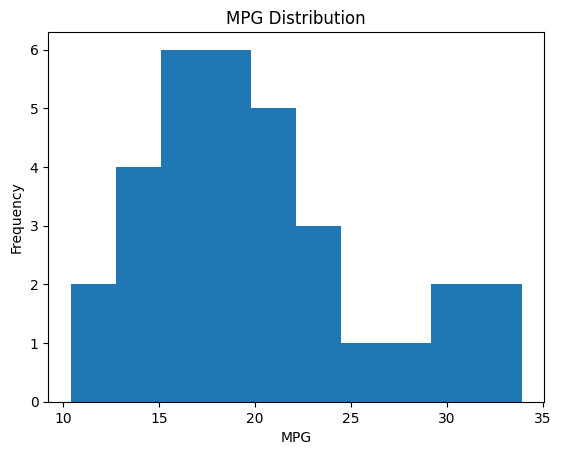

In [3]:
plt.hist(mtcars_data.mpg)
plt.xlabel("MPG")
plt.ylabel("Frequency")
plt.title("MPG Distribution")
plt.show()

# **Note**
1. Matplotlib doesn't have charts whch Seaborn  
   1.1. Ex: plt.pie() avail in matplotlib but not in Seaborn
2. Seaborn will not have some charts whch Matplotlib
3. Matplotlib and Seaborn will have same charts  
    3.2. Ex: plt.scatter(), sns.scatterplot() 

### 1.2 Countplot
- Discrete col

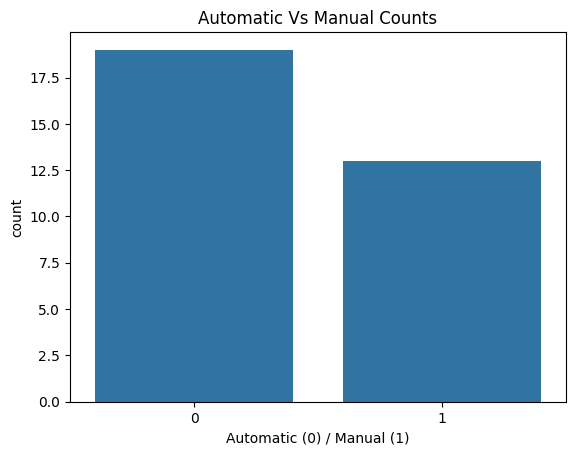

In [4]:
sns.countplot(data = mtcars_data, x = "am", y = None)
#sns.countplot(data = mtcars_data, x = None, y = "am")
plt.title("Automatic Vs Manual Counts")
plt.xlabel("Automatic (0) / Manual (1)")
plt.show()

### 1.3 Pie Chart
- Discrete

In [5]:
mtcars_data["cyl"].value_counts()

cyl
8    14
4    11
6     7
Name: count, dtype: int64

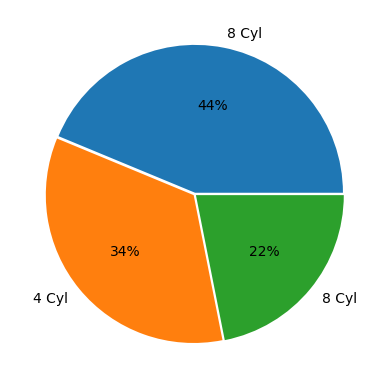

In [7]:
# plt.pie(data=mtcars_data, x = "mpg") # this gives messed display
plt.pie(data=mtcars_data, x = mtcars_data["cyl"].value_counts(), labels=["8 Cyl", "4 Cyl", "8 Cyl"], explode=[0.01,0.01,0.01], autopct="%1.0f%%")
plt.show()

## 2. Bivariate Analyis
**Important Charts:**
1. Barplot
2. Scatterplot

### 2.1 Barplot
- x is discrete
- y is contin

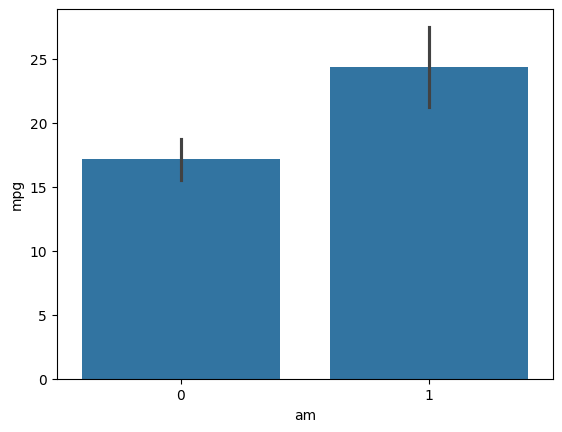

In [40]:
sns.barplot(data=mtcars_data, x="am", y= "mpg")
plt.show()

### 2.2 Scatterplot
* Compare the relation bet 2 Continuous data

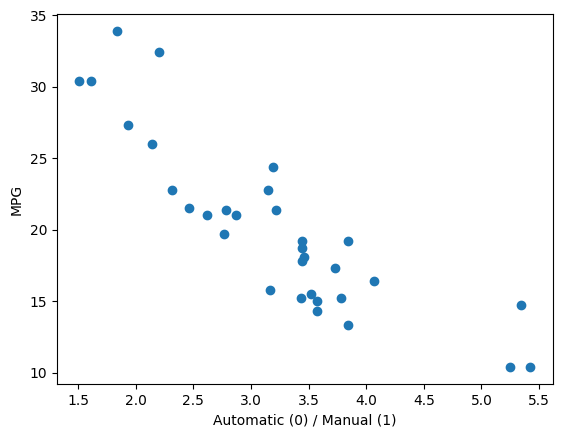

In [8]:
plt.scatter(data=mtcars_data, x = "wt", y = "mpg")
plt.xlabel("Automatic (0) / Manual (1)")
plt.ylabel("MPG")
plt.show()

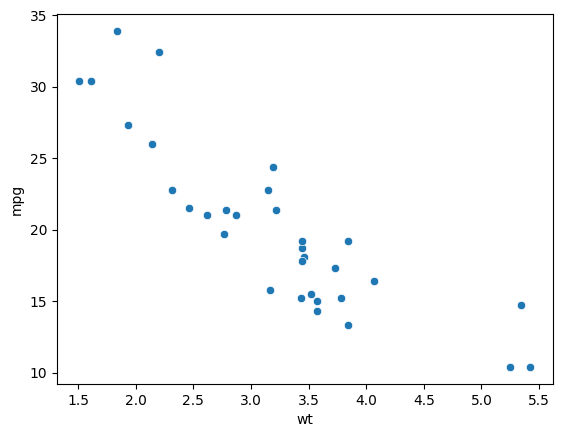

In [44]:
sns.scatterplot(data=mtcars_data, x = "wt", y = "mpg") # Looks similar
plt.show()

## 3. Multivariate Analysis
**Important Charts:**
1. Pairplot
2. Heatmap

### 3.1 Pairplot
* Compare all possibilities of numbered columns.

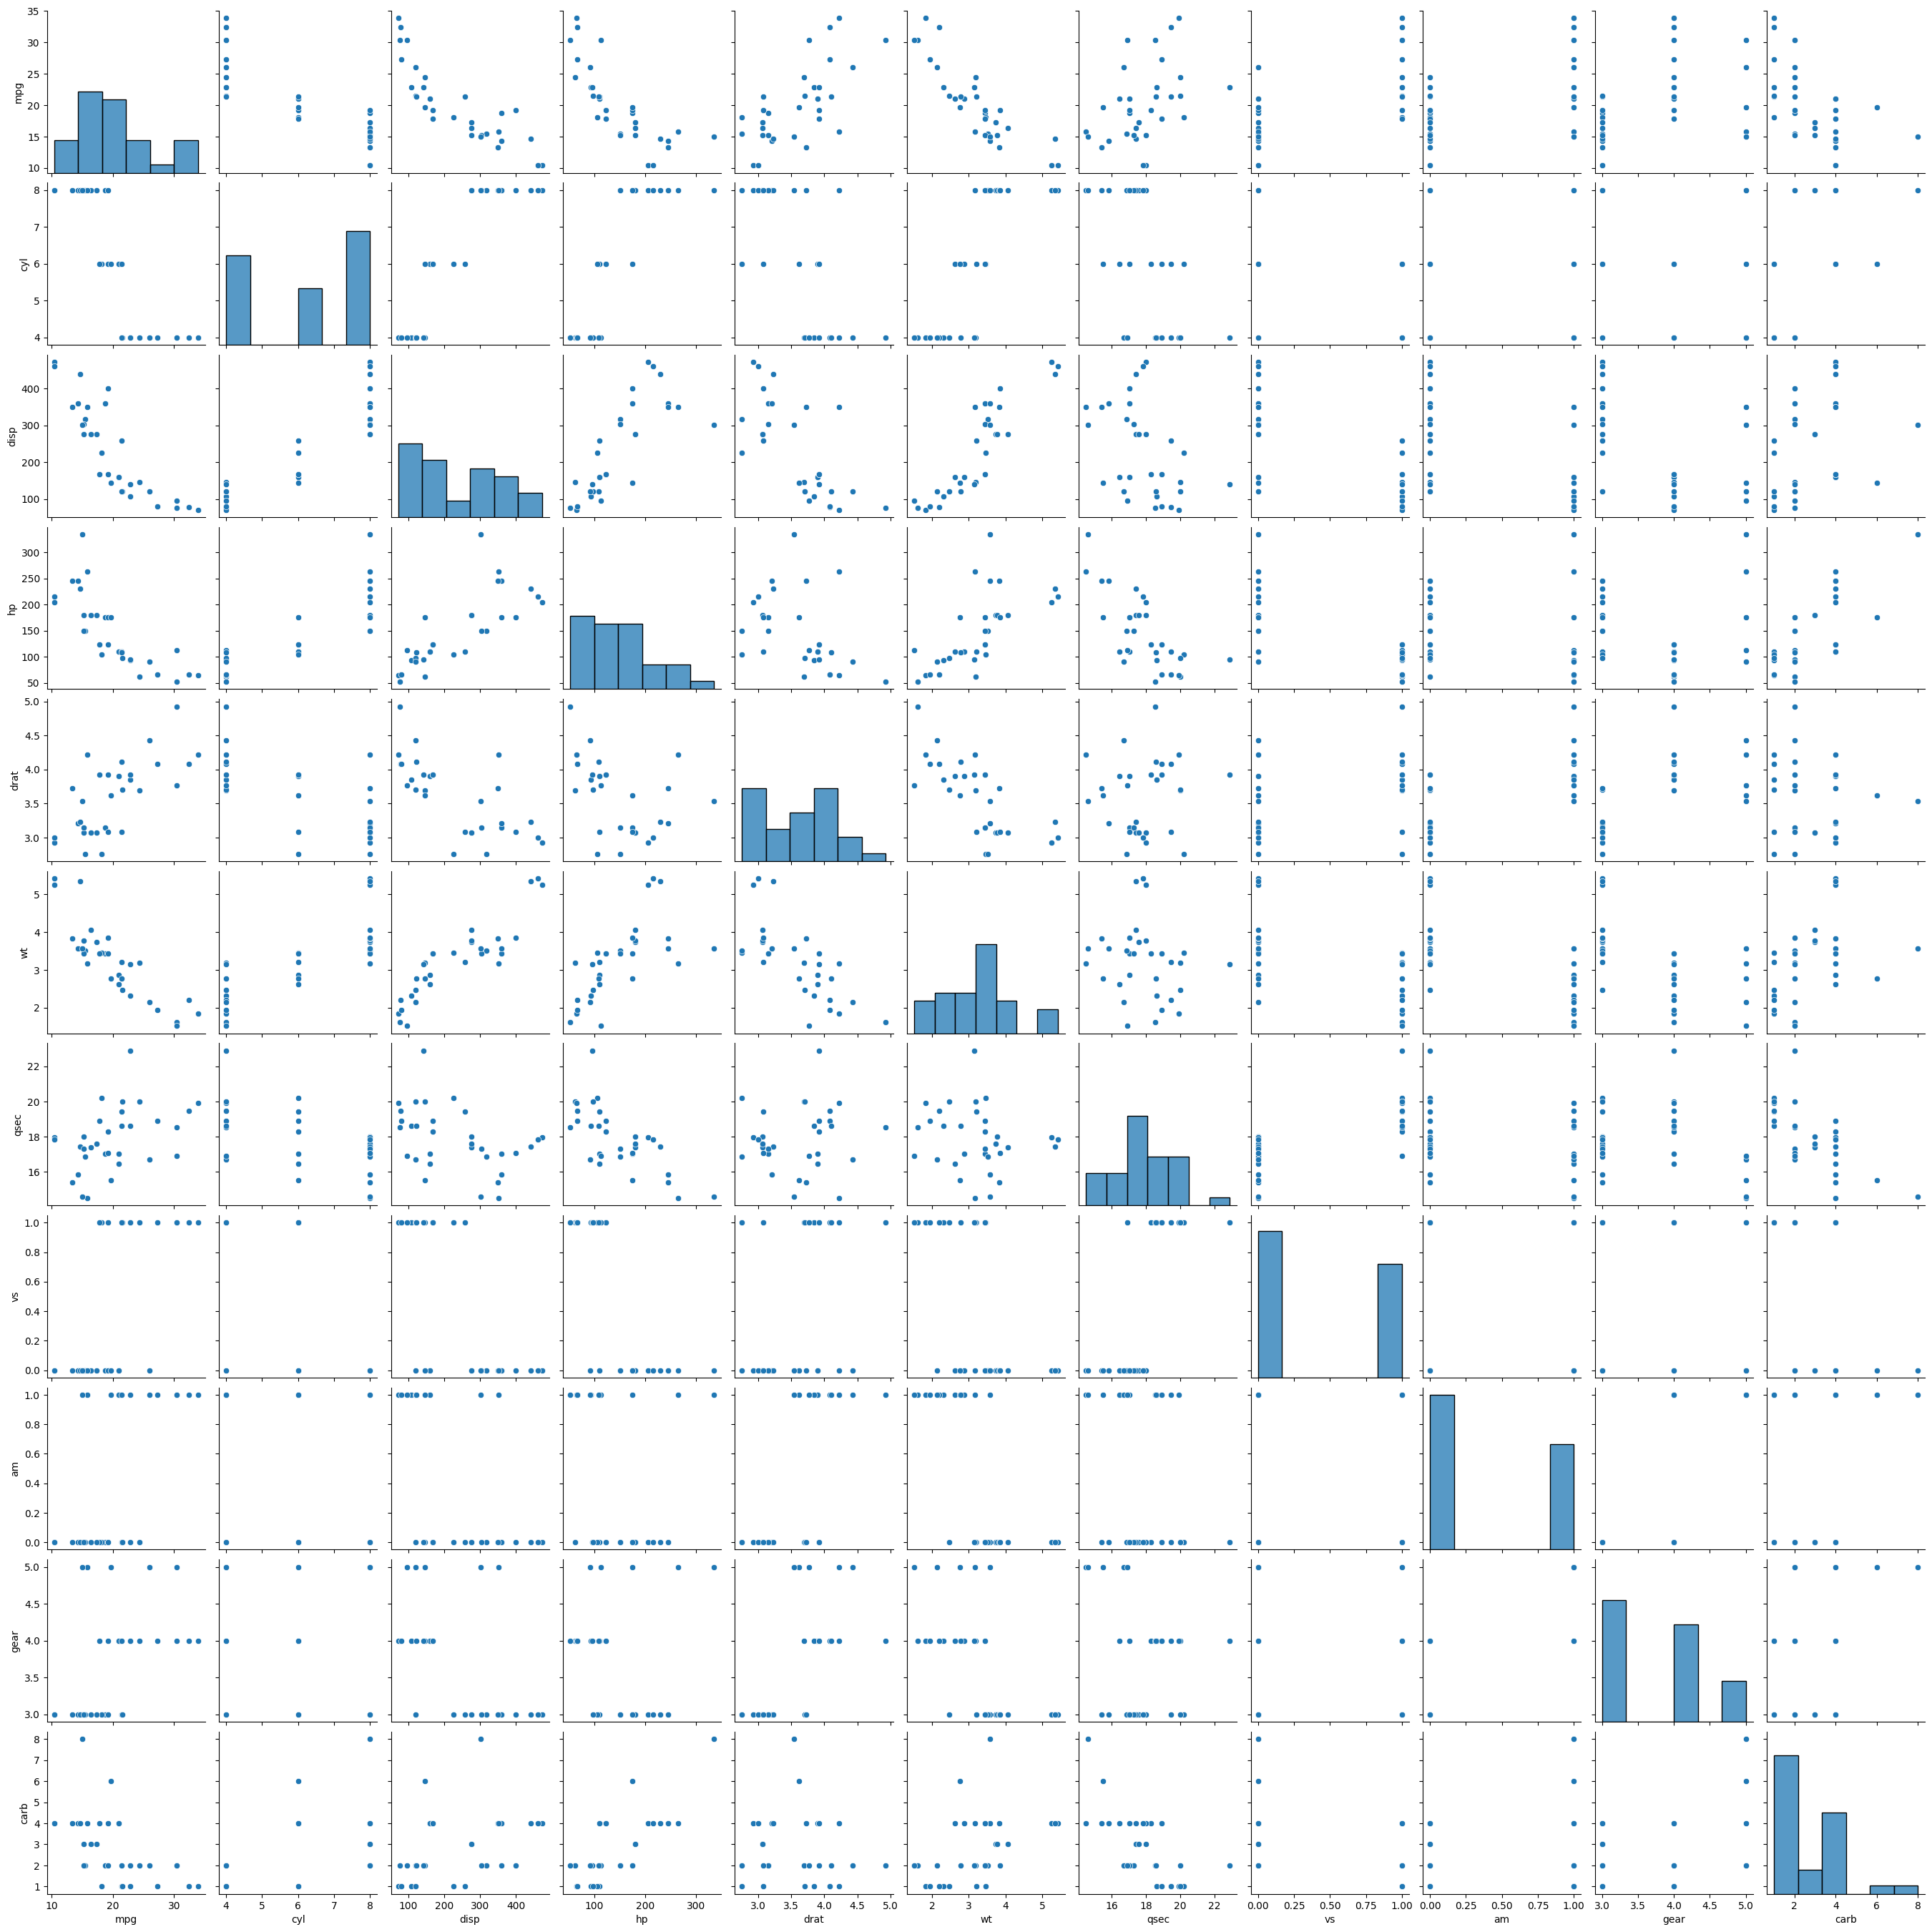

In [45]:
sns.pairplot(data=mtcars_data)

### 3.2 Heatmap

1. To identify the strength bet 2 features or columns (either it cold be Discrete Vs Conti or Contin Vs Discrete)
2. Diff types of methods: Pearson Correlation, Co.efficient, Spearmen Corr.Coeff)
    - Pearson Correlation : -1 to +1

In [ ]:
mtcars_data.corr() # this corr not allows text field so need to delete the model column

In [46]:
del mtcars_data["model"]

In [48]:
corr_matrix = mtcars_data.corr()
corr_matrix

,mpg,cyl,disp,hp,drat,wt,qsec,vs,am,gear,carb
mpg,1.000000,-0.852162,-0.847551,-0.776168,0.681172,-0.867659,0.418684,0.664039,0.599832,0.480285,-0.550925
cyl,-0.852162,1.000000,0.902033,0.832447,-0.699938,0.782496,-0.591242,-0.810812,-0.522607,-0.492687,0.526988
disp,-0.847551,0.902033,1.000000,0.790949,-0.710214,0.887980,-0.433698,-0.710416,-0.591227,-0.555569,0.394977
hp,-0.776168,0.832447,0.790949,1.000000,-0.448759,0.658748,-0.708223,-0.723097,-0.243204,-0.125704,0.749812
drat,0.681172,-0.699938,-0.710214,-0.448759,1.000000,-0.712441,0.091205,0.440278,0.712711,0.699610,-0.090790
wt,-0.867659,0.782496,0.887980,0.658748,-0.712441,1.000000,-0.174716,-0.554916,-0.692495,-0.583287,0.427606
qsec,0.418684,-0.591242,-0.433698,-0.708223,0.091205,-0.174716,1.000000,0.744535,-0.229861,-0.212682,-0.656249
vs,0.664039,-0.810812,-0.710416,-0.723097,0.440278,-0.554916,0.744535,1.000000,0.168345,0.206023,-0.569607
am,0.599832,-0.522607,-0.591227,-0.243204,0.712711,-0.692495,-0.229861,0.168345,1.000000,0.794059,0.057534
gear,0.480285,-0.492687,-0.555569,-0.125704,0.699610,-0.583287,-0.212682,0.206023,0.794059,1.000000,0.274073


<Axes: >

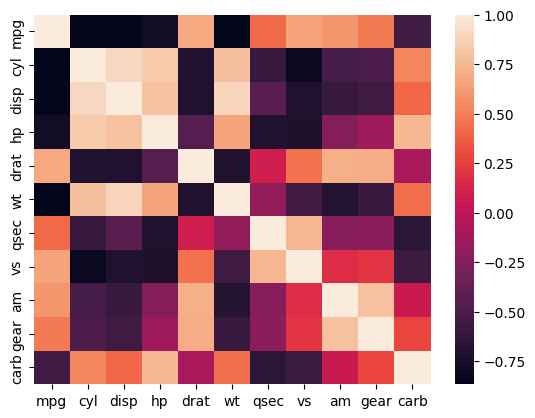

In [52]:
sns.heatmap(corr_matrix)
# darks are negative
# ligth colors are positive

<Axes: >

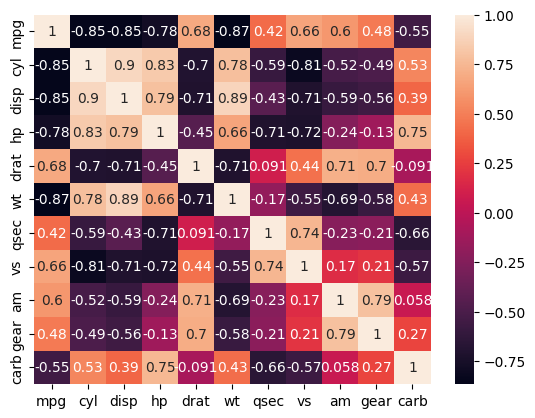

In [51]:
sns.heatmap(corr_matrix, annot=True) # annot is used to display the corr values

## ** Notes : **
0 to 0.20     - Very Weak Correlation  
0.21 to 0.40  - Weak Correlation  
0.41 to 0.60  - Normal/Strong Correlation  
0.61 to 0.80  - Strong Correlation  
0.81 to 1     - Very Strong Correlation

## End Intermmediate

==========================================================================================================

## Advance Level of Data Visualization

In [11]:
import plotly.express as px
df = px.data.gapminder().query("year == 2007").query("continent == 'Europe'")
df.head()

,country,continent,year,lifeExp,pop,gdpPercap,iso_alpha,iso_num
23,Albania,Europe,2007,76.423,3600523,5937.029526,ALB,8
83,Austria,Europe,2007,79.829,8199783,36126.492700,AUT,40
119,Belgium,Europe,2007,79.441,10392226,33692.605080,BEL,56
155,Bosnia and Herzegovina,Europe,2007,74.852,4552198,7446.298803,BIH,70
191,Bulgaria,Europe,2007,73.005,7322858,10680.792820,BGR,100


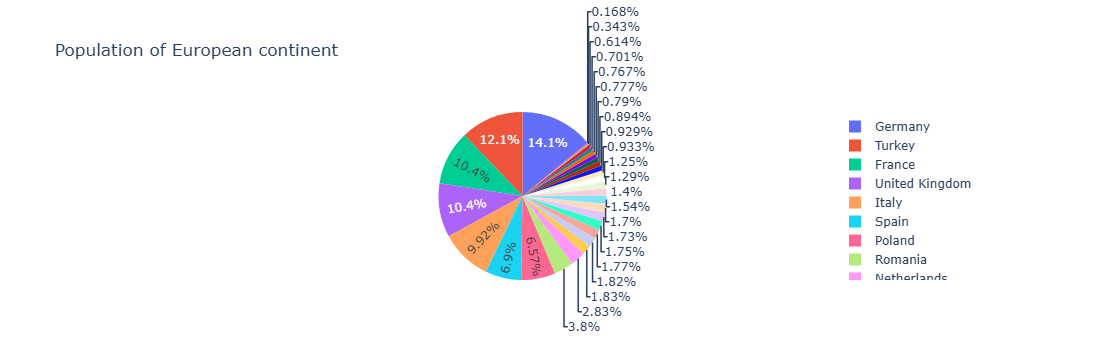

In [10]:


df.loc[df['pop'] < 2.e6, 'country'] = 'Other countries' # Represent only large countries
fig = px.pie(df, values='pop', names='country', title='Population of European continent')
fig.show()

## ** Note:**
1. Univariate charts can include more than one feature
2. Biviate  charts can include more than two feature

In [55]:
#sns.histplot()

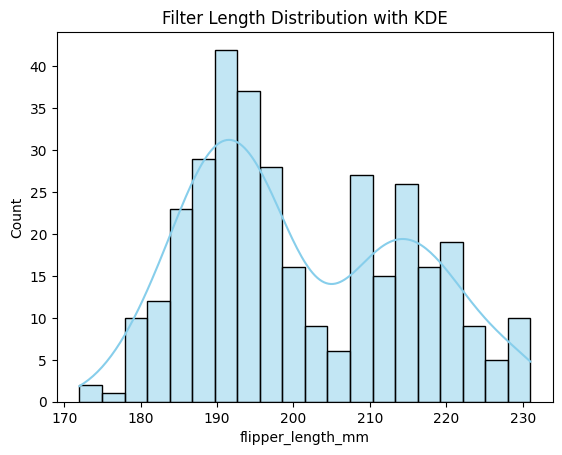

In [60]:
import seaborn as sns
import matplotlib.pyplot as plt

# Load sample dataset
penguins = sns.load_dataset("penguins")

# Create a basic histogram
sns.histplot(data=penguins, x="flipper_length_mm", kde=True, bins=20, color="skyblue")
plt.title("Filter Length Distribution with KDE")
plt.show()


In [62]:
penguins.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


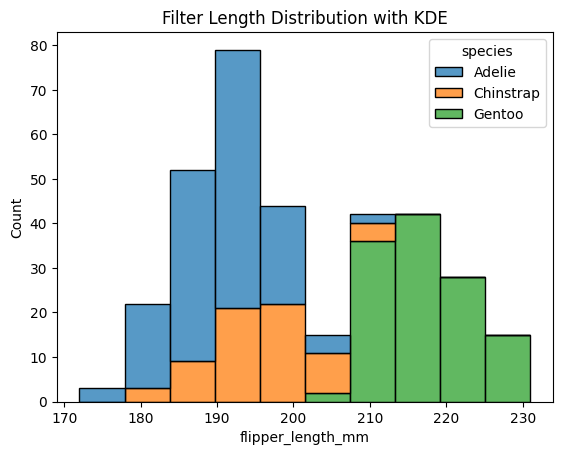

In [61]:
# Create a basic histogram
sns.histplot(data=penguins, x="flipper_length_mm", hue="species", multiple="stack")
plt.title("Filter Length Distribution with KDE")
plt.show()

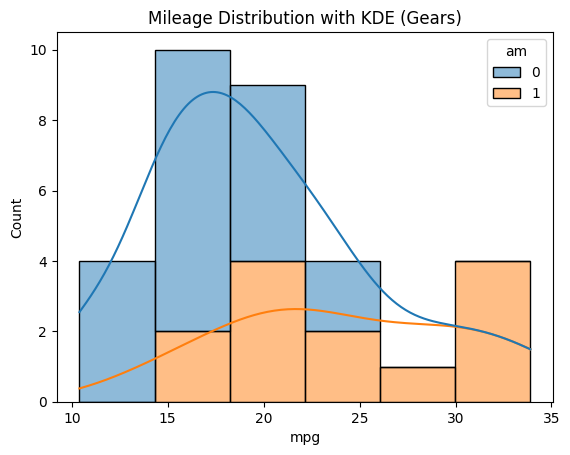

In [69]:
# our example

sns.histplot(data=mtcars_data, x="mpg", hue="am", kde=True, multiple="stack")
plt.title("Mileage Distribution with KDE (Gears)")
plt.show()